# SD · Чи видно машини згори і за якої роздільності?

**Тип:** виміряно. **Навіщо:** Чи видно транспорт у лісі на відкритих знімках і як точність залежить від роздільності.

Цей ноутбук повторює блок сторінки досліджень `web/science/#sd` і бере ті самі результати.

In [1]:
import sys
sys.path.insert(0, '..')
import pandas as pd
from eaglewings.ds import report
pd.set_option('display.width', 200)
%matplotlib inline

## Постановка, дані, протокол і метрики

Текст узято з модуля задачі, той самий записується в журнал кожного запуску.

In [2]:
print(report.protocol('SD'))

T11 (згори, супутник) і T18 (камери, фотопастки) · Детектори на відкритих еталонах: precision / recall замість «немає розмітки» в T4.

Це дві окремі задачі: run(part="aerial") — T11, VEDAI; run(part="ground") — T18, D-Fire і ENA24 (ds/tasks/cv_benchmark_ground.py).

Задача      скільки реально знаходять детектори і скільки дають хибних спрацювань. T4 цього порахувати не може: для парку
            немає розмітки. Тому міряємо на незалежних відкритих наборах, близьких за умовами, і чесно кажемо про різницю.
Дані        D-Fire (тест): 4306 фото, дим і вогонь, рамки.
            VEDAI: 2059 аерофото, переважно сільська місцевість, рамки машин; ніхто з моделей на ньому не вчився.
            Вихідні ~12,5 см/пкс штучно погіршуємо до 25 і 50 см/пкс: 50 см — це наші знімки Esri, де легкове авто ≈ 8–10 пкс.
            ENA24 (тест): 1337 кадрів фотопасток, 22 з машинами, решта тварини; лейбл кадру, без рамок.
Протокол    кадри випадково 50/50: на калібруванні обираємо поріг впевненості (max F

## Результат

Обраний підхід виділено. Вибір робився лише на валідації, числа тут з тесту.

,label,thr,ap50,ap50_ci,precision,recall
0,vedai_12cm · vehicle · yolo11x_obb,0.22,0.847,0.831–0.865,0.811,0.835
1,vedai_12cm · vehicle · grounding_dino,0.32,0.798,0.778–0.816,0.762,0.762
2,vedai_25cm · vehicle · yolo11x_obb,0.09,0.837,0.818–0.858,0.775,0.851
3,vedai_25cm · vehicle · grounding_dino,0.29,0.660,0.630–0.690,0.648,0.632
4,vedai_50cm · vehicle · yolo11x_obb,0.01,0.347,0.316–0.372,0.677,0.443
5,vedai_50cm · vehicle · grounding_dino,0.24,0.266,0.236–0.302,0.392,0.336


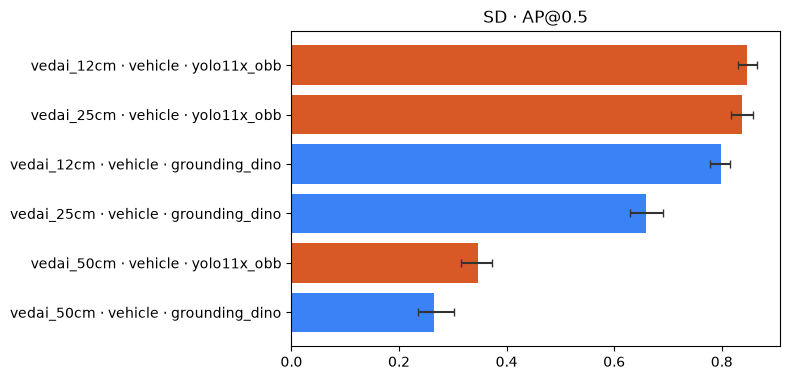

In [3]:
table, fig = report.show('SD')
table